# 🧠 Lesson 1: from the neuron to the layer

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mathsaicode/AILab/blob/main/notebooks/U01_S01_2026-11-23_neurona-y-capa/S01_2026-11-23_neurona-y-capa.ipynb)
![Unit](https://img.shields.io/badge/Unit-1-4F46E5)
![Week](https://img.shields.io/badge/Week-1-0D9488)
![Python](https://img.shields.io/badge/Python-3.10%2B-3776AB?logo=python&logoColor=white)
![NumPy](https://img.shields.io/badge/NumPy-013243?logo=numpy&logoColor=white)

*Created: 2026-11-23 · Last updated: 2026-11-23*

> 🎯 **Goal.** Compute, **by hand and with code**, the output of a layer of neurons for one data point or for a whole batch, and understand **what each symbol means and why the formula has this shape**:

$$y = Wx + b \qquad\text{and}\qquad Y = XW^{\top} + \mathbf{1}\,b^{\top}$$

## 🗺️ Lesson map

| Part | What you do | Planned for |
|---|---|---|
| 🐍 **A** | The four Python tools you need | Tue Nov 24 |
| 🧠 **B** | The neuron: by hand, with a loop, with `np.dot` | Wed Nov 25 |
| 🧱 **C** | The layer: several neurons, $Wx+b$ | Thu Nov 26 |
| 📦 **D** | Many data points at once | Fri Nov 27 |
| 🏁 **E** | Summary and closing questions | Fri Nov 27 |

## 🔁 How every step works

1. 🎯 **What we will achieve** in that step.
2. 💡 **The idea**, explained calmly (often connected to the math you already know).
3. 👀 **A worked example** that you only run and observe.
4. ✏️ **Your turn**: a cell with blanks `___` that you fill in, based on the example.
5. ✅ **Expected result**: the value that should come out, so you know whether you got there even without looking at the ✅.

> ▶️ Run the cells **in order**, from top to bottom. A red error is not a failure: its last line tells you what went wrong.

In [ ]:
import numpy as np

# The pictures live in src/ailab_viz.py. Locally we find the repo copy; on Colab it is downloaded.
import os, sys
from pathlib import Path
here = Path.cwd()
src = next((p / "src" for p in [here, *here.parents] if (p / "src" / "ailab_viz.py").exists()), None)
if src is not None:
    sys.path.append(str(src))
elif not os.path.exists("ailab_viz.py"):
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/mathsaicode/AILab/main/src/ailab_viz.py", "ailab_viz.py")
from ailab_viz import draw_list, draw_neuron, draw_hyperplane, draw_layer, draw_batch

def check(condition, ok_message, hint):
    # It only prints ✅ or ❌. You do not need to understand it.
    if condition:
        print("✅", ok_message)
    else:
        print("❌ Not yet.", hint)

print("All set")

All set


---
# 🐍 Part A: the four Python tools

Since you study mathematics, each tool has a mathematical equivalent you already know. Only the notation changes.

| Python | Mathematical equivalent |
|---|---|
| variable | a symbol to which we give a value |
| list | an $n$-tuple of numbers, like $(x_1,x_2,x_3)$ |
| `for` loop | a summation $\sum$ or any repeated operation |
| accumulator | a partial sum $S_k = S_{k-1} + a_k$ |

---
## A1. Variables

> 🎯 **What we will achieve:** Store numbers in variables and do a calculation with them.

#### 💡 The idea
A **variable** is a name to which a value is assigned. But there is an important difference from mathematics: in Python the `=` sign **is not an equality**, it is an **instruction**:

> *"Compute what is on the right and store it under the name on the left."*

That is why in Python it is valid to write `x = x + 1`, which is absurd as an equation: it means "take the current value of $x$, add 1 and store it back in $x$". This idea will be key when we accumulate sums.

The operators are `+` (addition), `-` (subtraction), `*` (multiplication), `/` (division). The function `print(...)` shows a result on screen.

#### 👀 Worked example (just run it)

In [ ]:
x = 2
w = 0.5
print(w * x)       # 1.0

x = x + 1          # take x, add 1 and store it again
print(x)           # 3

1.0
3


#### ✏️ Your turn
The simplest neuron has **one** input $x$, a weight $w$ and a bias $b$, and computes

$$y = w\,x + b$$

Complete the line for $y$.

In [ ]:
x = 2
w = 0.5
b = 1

y = ___      # write here the calculation: w times x plus b

check(y == 2, "Correct: y is 2", "It should be 0.5 * 2 + 1 = 2")

> ✅ **Expected result:** `y` is **2**.

---
## A2. Lists and indices

> 🎯 **What we will achieve:** Store several inputs together and pick out one specific element.

#### 💡 The idea
A real neuron has many inputs $x_1, x_2, x_3,\dots$. In Python they are stored in a **list**, with square brackets: `[2, 1, 3]`. It is the equivalent of the tuple $(x_1,x_2,x_3)$.

Each element is requested by its **position** (*index*) in square brackets. **In Python you start counting from 0**, whereas in mathematics we usually start at 1:

| Mathematics | $x_1$ | $x_2$ | $x_3$ |
|---|---|---|---|
| Python | `x[0]` | `x[1]` | `x[2]` |

It is the most common mistake when starting: the *second* element is `x[1]`. `len(x)` tells you how many elements there are.

#### 👀 Worked example (just run it)

In [ ]:
x = [2, 1, 3]

print(x[0])       # first element: 2
print(x[2])       # third element: 3
print(len(x))     # how many there are: 3

2
3
3


#### 🎨 Picture it
The same list, drawn. The top row is the math notation (it starts at 1); the bottom row is what Python uses (it starts at 0).

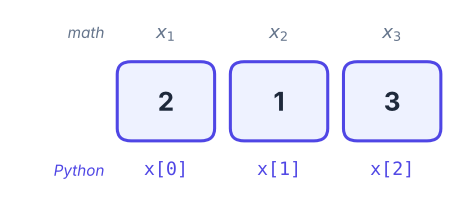

In [ ]:
draw_list([2, 1, 3], "x")

#### ✏️ Your turn
With $x=(2,1,3)$ and $w=(0.5,-1,2)$, compute the product of the **second** elements, that is $w_2\cdot x_2$.

In [ ]:
x = [2, 1, 3]
w = [0.5, -1, 2]

product = ___ * ___     # second element of w times second element of x

check(product == -1, "Correct: (-1) times 1 = -1", "Use w[1] and x[1]: the second one is at position 1")

> ✅ **Expected result:** `product` is **-1**.

---
## A3. The `for` loop

> 🎯 **What we will achieve:** Repeat an operation for each position of a list, without writing it out one by one.

#### 💡 The idea
A neuron with $784$ inputs cannot be computed by writing $784$ terms. A **summation** $\sum_{i=1}^{n}$ solves that in mathematics; the `for` **loop** solves it in Python:

```
for i in range(3):
    ...instructions...
```

- `range(3)` generates the numbers $0,1,2$ (it starts at 0 and stops **before** 3).
- On each pass, `i` takes one of those values.
- What gets repeated goes **indented** (spaces at the start of the line). In Python indentation is mandatory: it is how you say what is inside the loop.

#### 👀 Worked example (just run it)
Watch how `i` changes and how `x[i]` walks through the list.

In [ ]:
x = [2, 1, 3]

for i in range(3):
    print("i =", i, "   x[i] =", x[i])

i = 0    x[i] = 2
i = 1    x[i] = 1
i = 2    x[i] = 3


> ✅ **Expected result:** Three lines: `i = 0 x[i] = 2`, `i = 1 x[i] = 1`, `i = 2 x[i] = 3`.

---
## A4. The accumulator (adding many things)

> 🎯 **What we will achieve:** Add all the elements of a list using a loop.

#### 💡 The idea
A sum of many terms is built through **partial sums**:

$$S_0=0,\qquad S_k = S_{k-1} + a_k$$

In Python this is written with a variable that **keeps growing**:

```
total = 0
total = total + 5
```

The second line is not an equation: it says "take what was in `total`, add 5 and store it again in `total`". Inside a loop, that line runs once per element.

#### 👀 Worked example (just run it)
We add $1+2+3$.

In [ ]:
numbers = [1, 2, 3]

total = 0                       # S_0 = 0
for i in range(3):
    total = total + numbers[i]  # S_k = S_(k-1) + a_k
    print("after pass", i, "the total is", total)

after pass 0 the total is 1
after pass 1 the total is 3
after pass 2 the total is 6


#### ✏️ Your turn
Now add the elements of the list `[10, 20, 30]`.

In [ ]:
numbers = [10, 20, 30]

total = 0
for i in range(3):
    total = ___ + numbers[i]      # what was already in total, plus element i

check(total == 60, "Correct: 10 + 20 + 30 = 60", "Write total + numbers[i]. It should give 60")

> ✅ **Expected result:** `total` is **60**.

---
# 🧠 Part B: the neuron

## 🧭 The full idea, before programming

### A neuron is a weighted vote
Imagine you want to decide whether a photo shows a cat. You have several input values $x_1,\dots,x_n$ (for example, the brightness of each pixel). Each value "votes" for or against, but **not all votes are worth the same**. The weight $w_i$ says how much the vote of value $i$ is worth:

- $w_i>0$: that value pushes the result up.
- $w_i<0$: it pushes it down.
- $w_i\approx 0$: it barely matters.

All the weighted votes are added and a fixed number $b$, the **bias**, is included:

$$y=\sum_{i=1}^{n} w_i x_i + b = w^{\top}x + b$$

### What is the bias $b$ for?
Without $b$, the neuron would always equal $0$ when all the inputs are $0$. Geometrically, the equation $w^{\top}x = 0$ describes a hyperplane that **passes through the origin**. With $b$, the hyperplane $w^{\top}x+b=0$ can sit anywhere: $b$ shifts it. It is the constant term of a linear equation, and it is what lets the neuron "fire" more easily or less easily.

### What $y$ means
$y$ is a number that measures **how much the data point resembles what the neuron is looking for**. To classify, we look at its sign: $y>0$ on one side of the hyperplane, $y<0$ on the other. That is why a neuron is a **linear classifier**.

#### 🎨 Picture it: a neuron
Three inputs, each multiplied by its weight, added together with the bias. Teal arrows push the result up, rose arrows push it down, and thicker arrows matter more.

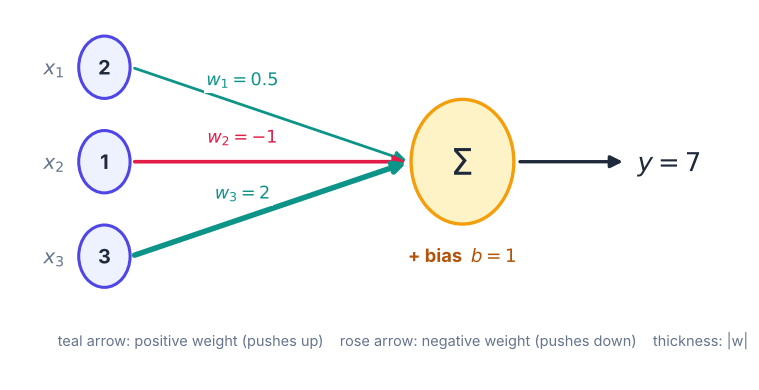

In [ ]:
draw_neuron(x=[2, 1, 3], w=[0.5, -1, 2], b=1)

#### 🎨 Picture it: what the bias does
In two dimensions, $w^{\top}x+b=0$ is a line. The vector $w$ is perpendicular to it, and the bias slides the line away from the origin. The signed distance of the highlighted point is the number $\dfrac{w^{\top}x+b}{\|w\|}$. This is hand exercise 2.

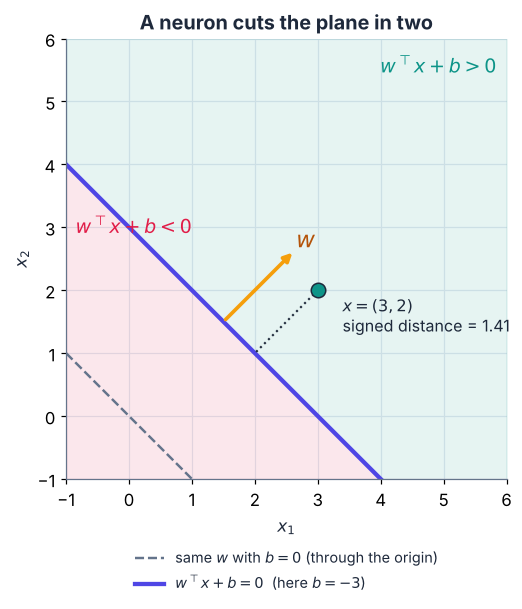

In [ ]:
draw_hyperplane(w=[1, 1], b=-3, point=(3, 2))

---
## B1. The neuron computed by hand

> 🎯 **What we will achieve:** Compute $y$ by writing out each term, to see exactly what happens.

#### 👀 Worked example (just run it)
With $x=(1,2)$, $w=(3,4)$ and $b=5$:

$$y = 3\cdot 1 + 4\cdot 2 + 5 = 3 + 8 + 5 = 16$$

In [ ]:
x = [1, 2]
w = [3, 4]
b = 5

y = w[0]*x[0] + w[1]*x[1] + b
print(y)       # 16

16


#### ✏️ Your turn
Now with $x=(2,1,3)$, $w=(0.5,-1,2)$ and $b=1$. Write the three products and the bias:

$$y = 0.5\cdot 2 + (-1)\cdot 1 + 2\cdot 3 + 1$$

In [ ]:
x = [2, 1, 3]
w = [0.5, -1, 2]
b = 1

y = ___      # w[0]*x[0] + w[1]*x[1] + ... + b

check(y == 7, "Correct: y = 7", "It should be 7. Check that you added the three products and b")

> ✅ **Expected result:** $1 + (-1) + 6 + 1 = \mathbf{7}$.

---
## B2. The neuron with a loop

> 🎯 **What we will achieve:** Compute the same thing with a loop, which works for any number of inputs.

#### 💡 The idea
It is the summation $\sum_i w_i x_i + b$ turned into code. We use the accumulator from A4, but instead of starting at $0$ **we start at $b$**, because the bias is always added exactly once:

1. `y = b`
2. On each pass: `y = y + w[i] * x[i]`

#### 👀 Worked example (just run it)
With $x=(1,2)$, $w=(3,4)$, $b=5$ it should give $16$ again.

In [ ]:
x = [1, 2]
w = [3, 4]
b = 5

y = b
for i in range(len(x)):
    y = y + w[i] * x[i]

print(y)       # 16

16


#### ✏️ Your turn
The same loop with the data from B1.

In [ ]:
x = [2, 1, 3]
w = [0.5, -1, 2]
b = 1

y = ___                  # initial value of the accumulator
for i in range(len(x)):
    y = y + ___          # the product of w[i] and x[i]

check(y == 7, "Correct: the loop gives the same as the hand calculation", "It should be 7. y starts at b and adds w[i] * x[i]")

> ✅ **Expected result:** `y` is **7**, the same as in B1.

---
## B3. NumPy: real vectors

> 🎯 **What we will achieve:** Meet the object we will use from now on: the **NumPy array**.

#### 💡 The idea
A Python list stores numbers but does not know how to do algebra. A **NumPy array** (`np.array`) does behave like a vector of $\mathbb{R}^n$: operations are applied **element by element**. All of modern AI is computed with these objects, because they are much faster than loops.

#### 👀 Worked example (just run it)
Notice the difference between multiplying a list and an array.

In [ ]:
my_list = [2, 1, 3]
arr     = np.array([2, 1, 3])

print("list * 2  =", my_list * 2)     # with lists, * 2 REPEATS the list
print("array * 2 =", arr * 2)         # with arrays, it multiplies each element

w = np.array([0.5, -1, 2])
print("w * arr   =", w * arr)         # element-by-element product

list * 2  = [2, 1, 3, 2, 1, 3]
array * 2 = [4 2 6]
w * arr   = [ 1. -1.  6.]


> ✅ **Expected result:** `list * 2` gives `[2, 1, 3, 2, 1, 3]`; `array * 2` gives `[4 2 6]`; `w * arr` gives `[1. -1. 6.]`. If you add up that last result and add $b=1$, you get $7$ again.

---
## B4. The dot product

> 🎯 **What we will achieve:** Compute the whole neuron in **a single line**.

#### 💡 The idea
The sum of the element-by-element products is exactly the **dot product** (inner product) you already know:

$$w^{\top}x = \sum_{i=1}^{n} w_i x_i$$

NumPy computes it with `np.dot(a, b)`: it takes **two** vectors separated by a comma. So the neuron becomes

$$y = w^{\top}x + b \;\;\longrightarrow\;\; \texttt{np.dot(w, x) + b}$$

#### 👀 Worked example (just run it)

In [ ]:
x = np.array([1, 2])
w = np.array([3, 4])
b = 5

y = np.dot(w, x) + b
print(y)       # 16

16


#### ✏️ Your turn

In [ ]:
x = np.array([2, 1, 3])
w = np.array([0.5, -1, 2])
b = 1

y = ___      # np.dot(w, x) plus b

check(y == 7, "Correct: one line does the work of the whole loop", "It should be 7. Write np.dot(w, x) + b")

> ✅ **Expected result:** `y` is **7**. You now have the neuron in three different ways (by hand, loop and `np.dot`) and all three agree.

---
# 🧱 Part C: the layer

## 🧭 The full idea, before programming

### Several neurons looking at the same thing
A single neuron produces **one** number. A **layer** has $m$ neurons that receive **the same $n$ inputs**, but each with **its own** weights and its own bias. This way each neuron looks for a different pattern in the same data, and the layer produces **$m$ numbers**.

### The matrix $W$
The weights of the $m$ neurons are stored in a matrix $W\in\mathbb{R}^{m\times n}$ where **row $j$ holds the weights of neuron $j$**:

$$W=\begin{pmatrix} W_{11}&W_{12}&\cdots&W_{1n}\\ W_{21}&W_{22}&\cdots&W_{2n}\\ \vdots&&&\vdots\\ W_{m1}&W_{m2}&\cdots&W_{mn}\end{pmatrix}$$

The biases go in a vector $b\in\mathbb{R}^m$ (one per neuron). The output of neuron $j$ is

$$y_j=\sum_{i=1}^{n} W_{ji}\,x_i + b_j$$

### It is an affine transformation
If you remember Linear Algebra, $x\mapsto Wx$ is a **linear transformation** from $\mathbb{R}^n$ to $\mathbb{R}^m$, and adding $b$ is a **translation**. A linear transformation plus a translation is called **affine**. Every dense layer in a neural network is an affine transformation.

### Table of dimensions
| Object | What it is | Shape |
|---|---|---|
| $x$ | inputs | $n$ |
| $W$ | weights | $m\times n$ |
| $b$ | biases | $m$ |
| $y$ | outputs | $m$ |

Rule so you don't get lost: **the rows of $W$ are the neurons, the columns are the inputs**.

#### 🎨 Picture it: a layer
Every input is connected to every neuron. Row $j$ of $W$ holds the weights of neuron $j$, and each neuron adds its own bias.

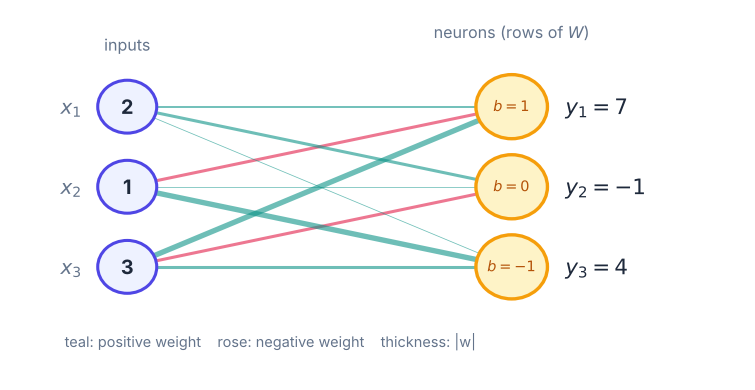

In [ ]:
draw_layer(W=[[0.5, -1, 2], [1, 0, -1], [0, 2, 1]], b=[1, 0, -1], x=[2, 1, 3])

---
## C1. Looking at a matrix

> 🎯 **What we will achieve:** See how $W$ is stored in NumPy and how to ask for one row.

#### 👀 Worked example (just run it)

In [ ]:
W = np.array([[0.5, -1,  2],      # weights of neuron 0
              [1.0,  0, -1],      # weights of neuron 1
              [0.0,  2,  1]])     # weights of neuron 2
b = np.array([1, 0, -1])          # one bias per neuron
x = np.array([2, 1, 3])

print("shape of W:", W.shape)         # (3, 3): 3 neurons, 3 inputs
print("neuron 0:", W[0])              # row 0
print("neuron 2:", W[2])
print("bias of neuron 2:", b[2])

shape of W: (3, 3)
neuron 0: [ 0.5 -1.   2. ]
neuron 2: [0. 2. 1.]
bias of neuron 2: -1


> ✅ **Expected result:** `shape of W: (3, 3)`, the row `[ 0.5 -1.  2. ]` for neuron 0, the row `[0. 2. 1.]` for neuron 2 and the bias `-1`.

---
## C2. The layer, neuron by neuron

> 🎯 **What we will achieve:** Compute $y_j$ for **each** neuron using the dot product from B4 and a loop over the neurons.

#### 💡 The idea
Neuron $j$ is exactly B4, but with **row $j$ of $W$** as the weight vector:

$$y_j=\texttt{np.dot(W[j], x)} + b_j$$

A loop runs through $j=0,1,\dots,m-1$ and stores each output in a list with `.append(...)`.

#### 👀 Worked example (just run it)
A layer with **2 neurons** and **2 inputs**: $W=\begin{pmatrix}1&2\\3&4\end{pmatrix}$, $b=(0,1)$, $x=(1,1)$. By hand:

$$y_0 = 1\cdot1+2\cdot1+0 = 3,\qquad y_1 = 3\cdot1+4\cdot1+1 = 8$$

In [ ]:
W_ex = np.array([[1, 2],
                 [3, 4]])
b_ex = np.array([0, 1])
x_ex = np.array([1, 1])

y_ex = []                                   # empty list
for j in range(2):                          # one pass per neuron
    output = np.dot(W_ex[j], x_ex) + b_ex[j]
    y_ex.append(output)                     # add to the end of the list

print(np.array(y_ex))      # [3 8]

[3 8]


#### ✏️ Your turn
Do the same with the layer from C1 (3 neurons, 3 inputs). Notice that only the variable names and the number of passes change.

In [ ]:
y = []
for j in range(3):
    output = ___          # same as above, but with W, x and b from C1
    y.append(output)

y = np.array(y)
print("y =", y)
check(np.allclose(y, [7, -1, 4]), "Correct: y = [7, -1, 4]", "It should be [7, -1, 4]. Use np.dot(W[j], x) + b[j]")

> ✅ **Expected result:** $y=(7,\,-1,\,4)$. Check it by hand: neuron 0 gives $1-1+6+1=7$; neuron 1 gives $2+0-3+0=-1$; neuron 2 gives $0+2+3-1=4$.

---
## C3. The layer in one line: $Wx+b$

> 🎯 **What we will achieve:** Replace the whole loop with the formula of the lesson.

#### 💡 The idea
The product of a matrix and a vector **is**, by definition, "take the dot product of each row with the vector". That is, the loop in C2 is exactly $Wx$. In NumPy the matrix product is written with the `@` operator:

$$y = Wx + b \;\;\longrightarrow\;\; \texttt{W @ x + b}$$

#### 👀 Worked example (just run it)
With the small layer from C2 it should give the same as the loop: $(3, 8)$.

In [ ]:
print(W_ex @ x_ex + b_ex)       # [3 8]

[3 8]


#### ✏️ Your turn
With the layer from C1.

In [ ]:
y = ___      # W @ x plus b

check(np.allclose(y, [7, -1, 4]), "Correct: the loop and W @ x + b give the same", "It should be [7, -1, 4]. Write W @ x + b")

> ✅ **Expected result:** $y=(7,-1,4)$, the same result as the loop. **This is the central formula of the lesson.**

---
# 📦 Part D: many data points at once

## 🧭 The full idea, before programming

### Why a batch
In practice a network does not process one data point at a time, but a **batch** of $N$ examples together: it is much faster and it is what training will use. We store the batch in a matrix $X\in\mathbb{R}^{N\times n}$ where **each row is one example**.

### Why the transpose appears
For **one** example, the output is $y=Wx+b$ with $x$ as a column. But in the batch each example $x_k$ is a **row** of $X$. Let us transpose the formula (remembering that $(AB)^{\top}=B^{\top}A^{\top}$):

$$y_k^{\top} = (Wx_k+b)^{\top} = x_k^{\top}\,W^{\top} + b^{\top}$$

That is, the output of example $k$ (as a row) is the row $x_k^\top$ multiplied by $W^\top$, plus $b^\top$. Stacking the $N$ rows:

$$Y = XW^{\top} + \mathbf{1}\,b^{\top}$$

where $\mathbf{1}$ is a vector of ones that repeats the bias in every row. NumPy does that repetition by itself (*broadcasting*), so it is written `X @ W.T + b`.

### Checking shapes
$X$ is $N\times n$, $W^{\top}$ is $n\times m$, so $XW^{\top}$ is $N\times m$: **one row per example, one column per neuron**. The inner dimensions ($n$ with $n$) must match; if they don't, NumPy raises an error.

#### 🎨 Picture it: a batch
The whole formula $Y = XW^{\top} + b$ with real numbers. The highlighted row of $X$ (example 0) becomes the highlighted row of $Y$.

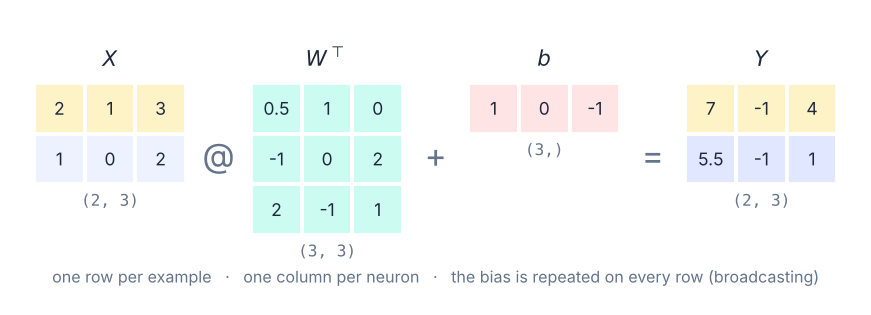

In [ ]:
draw_batch(X=[[2, 1, 3], [1, 0, 2]], W=[[0.5, -1, 2], [1, 0, -1], [0, 2, 1]], b=[1, 0, -1])

---
## D1. Looking at shapes

> 🎯 **What we will achieve:** Learn to read `.shape`, which is the tool for catching errors in neural networks.

#### 👀 Worked example (just run it)

In [ ]:
X = np.array([[2, 1, 3],      # example 0
              [1, 0, 2]])     # example 1

print("X   :", X.shape,   "→ 2 examples, 3 inputs")
print("W   :", W.shape,   "→ 3 neurons, 3 inputs")
print("W.T :", W.T.shape, "→ the transpose swaps rows and columns")
print("(2,3) times (3,3) gives (2,3): one row per example, one column per neuron")

X   : (2, 3) → 2 examples, 3 inputs
W   : (3, 3) → 3 neurons, 3 inputs
W.T : (3, 3) → the transpose swaps rows and columns
(2,3) times (3,3) gives (2,3): one row per example, one column per neuron


---
## D2. The full batch

> 🎯 **What we will achieve:** Compute the output of **all** the examples with a single line.

#### 👀 Worked example (just run it)
With the small layer from C2 and two examples $x_0=(1,1)$ and $x_1=(2,0)$. By hand, $y_0=(3,8)$ and $y_1=(1\cdot2+0+0,\;3\cdot2+0+1)=(2,7)$.

In [ ]:
X_ex = np.array([[1, 1],
                 [2, 0]])

Y_ex = X_ex @ W_ex.T + b_ex
print(Y_ex)       # [[3 8]
                  #  [2 7]]

[[3 8]
 [2 7]]


#### ✏️ Your turn
With the batch $X$ from D1 and the layer from C1.

In [ ]:
Y = ___      # X @ W.T plus b

print(Y)
check(np.allclose(Y, [[7, -1, 4], [5.5, -1, 1]]), "Correct: each row of Y is the output of one example", "Write X @ W.T + b. The first row should be [7, -1, 4]")

### ✅ Expected result
$$Y=\begin{pmatrix}7&-1&4\\5.5&-1&1\end{pmatrix}$$
The first row matches the result from C3, because example 0 is the same $x$.

Check the second row by hand: $x_1=(1,0,2)$ gives $0.5+0+4+1=5.5$; $1+0-2+0=-1$; $0+0+2-1=1$.

---
# 🏁 Part E: summary

## What you achieved
1. A **neuron** is $y=w^{\top}x+b$: a weighted vote.
2. A **layer** stacks $m$ neurons in a matrix $W$ (each row, one neuron): $y=Wx+b$, an affine transformation.
3. A **batch** of $N$ examples is processed at once with $Y=XW^{\top}+\mathbf{1}b^{\top}$.
4. `.shape` tells you whether the dimensions fit.

## What is missing (next lessons)
If you stack two affine layers with nothing between them, the result is still **a single** affine transformation: you gain no power. That is why in the next unit we add a nonlinear **activation function** between layers. And then we will see how $W$ and $b$ are adjusted (training).

## Closing questions
Answer them in a text cell, in your own words:
1. What does each **row** of $W$ represent? And each **column**?
2. What shape does $W$ have if a layer has 784 inputs and 10 neurons? How many parameters does it have in total (counting $b$)?
3. Why is $XW^{\top}$ used for the batch, and not $WX$?

---
## Appendix (just observe, not needed today): the layer as an object
Later we will package the above into a *class* so that layers can be stacked. For now it is enough to see that it is **the same calculation**, with $W$ and $b$ stored inside the object.

In [ ]:
class DenseLayer:
    def __init__(self, n_inputs, n_neurons):
        self.W = 0.01 * np.random.randn(n_neurons, n_inputs)   # (neurons, inputs)
        self.b = np.zeros(n_neurons)                           # one bias per neuron

    def forward(self, X):
        return X @ self.W.T + self.b                           # the same calculation as D2

layer = DenseLayer(3, 4)
print(layer.forward(X).shape)    # (2, 4)

(2, 4)


---

➡️ **Next:** Lesson 2 adds a nonlinear activation between layers and a measure of error, so the network finally has something to improve.